# 철강 공장 전력 사용 분석 (2018)

UCI *Steel Industry Energy Consumption* 데이터로 한 공장의 1년치 15분 단위 전력 기록을 분석한다. UCI 설명에 따르면 데이터는 전남 광양의 대우제철(DAEWOO Steel Co. Ltd)에서 수집되었다(Sathishkumar, Shin & Cho, 2021, *Building Research & Information* 49(1)).

이 노트북은 분석가를 위한 작업 기록이다. 결론만 필요하면 `build/report.html`(보고서)이나 `build/dashboard.html`(대시보드)을 먼저 보면 된다.

분석 로직은 모두 `src/steelenergy/`에 있다. 이 노트북은 그 함수를 순서대로 호출하고 결과를 해석한다. 본문의 수치는 `notebooks/build_notebook.py`가 같은 파이프라인 결과로 채운 것이다.

**질문과 답**

| 질문 | 답 |
|---|---|
| 1. 전력은 언제, 얼마나 몰려서 쓰이는가? | 평일 08–18시는 1년 시간의 30%지만 사용량의 64%가 이때 쓰인다. 15분 기록의 53%는 거의 멈춘 상태(전력 중앙값 약 13 kW)다. |
| 2. 소비량과 부하 구분(`Load_Type`)은 얼마나 예측 가능한가? | 15분 뒤 사용량을 평균 오차 3.94 kWh(WAPE 16%)로 예측한다. '직전값 그대로' 대비 24% 개선이다. `Load_Type`은 계절별 요금 시간표다(역방향 분할 macro-F1 0.96, 요일·시각·계절 시간표만으로 0.88). |
| 3. 평소와 다르게 쓴 날은 언제인가? | 평일 공휴일 15일 중 7일, 공휴일이 아닌 평일 5일이 휴무였다. 그 밖의 이상 일자는 2일이다. |
| 4. 비용과 무효전력을 줄일 여지는? | 역률을 0.95로 보상하면 무효전력량이 39% 줄어든다. 최대부하 시간대 사용량 10%를 옮기면 가정 요금 기준 연 481만 원이 절감된다. |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from steelenergy import anomaly, config, eda, features, io, labels, plots, scenarios, stats, validate
from steelenergy.models import classify, regress, split

plots.setup()
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)

## 1. 데이터 이해

원본 컬럼과 코드에서 쓰는 이름은 아래와 같다. 역률은 원본 그대로 % 단위다. 본문에서는 0–1 비율로 바꿔 쓴다(예: 90.3% → 0.903).

| 원본 | 코드 | 뜻 | 단위 |
|---|---|---|---|
| `date` | `timestamp` | 15분 구간이 끝나는 시각 | 일/월/연 시:분 |
| `Usage_kWh` | `kwh` | 유효전력량: 실제로 일을 한 전력 | kWh / 15분 |
| `Lagging_Current_Reactive.Power_kVarh` | `lag_kvarh` | 지상 무효전력량: 전동기·변압기처럼 코일이 있는 설비에서 오가는 전력 | kVarh / 15분 |
| `Leading_Current_Reactive_Power_kVarh` | `lead_kvarh` | 진상 무효전력량: 콘덴서 쪽 무효전력 | kVarh / 15분 |
| `CO2(tCO2)` | `co2_t` | 배출량 | tCO₂ / 15분 |
| `Lagging_Current_Power_Factor` | `lag_pf` | 지상 역률 | % |
| `Leading_Current_Power_Factor` | `lead_pf` | 진상 역률 | % |
| `NSM` | `nsm` | 자정 이후 초 | 초 |
| `WeekStatus`, `Day_of_week` | `week_status`, `day_of_week` | 주중·주말, 요일 | |
| `Load_Type` | `load_type` | 부하 구분(Light/Medium/Maximum) | |

15분 사용량(kWh)에 4를 곱하면 그 15분 동안의 평균 전력(kW)이 된다.

In [2]:
raw = io.read_csv()
raw.head()

,timestamp_raw,kwh,lag_kvarh,lead_kvarh,co2_t,lag_pf,lead_pf,nsm,week_status,day_of_week,load_type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


날짜는 일-월-연 순서다. 그런데 파일을 그대로 파싱하면 시간 순서가 맞지 않는다.

In [3]:
naive = pd.to_datetime(raw["timestamp_raw"], format="%d/%m/%Y %H:%M")
print("단조 증가:", naive.is_monotonic_increasing)
raw.iloc[93:98]

단조 증가: False


,timestamp_raw,kwh,lag_kvarh,lead_kvarh,co2_t,lag_pf,lead_pf,nsm,week_status,day_of_week,load_type
93,01/01/2018 23:30,3.24,2.95,0.0,0.0,73.94,100.0,84600,Weekday,Monday,Light_Load
94,01/01/2018 23:45,3.67,3.96,0.0,0.0,67.97,100.0,85500,Weekday,Monday,Light_Load
95,01/01/2018 00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load
96,02/01/2018 00:15,3.20,3.10,0.0,0.0,71.82,100.0,900,Weekday,Tuesday,Light_Load
97,02/01/2018 00:30,3.85,4.61,0.0,0.0,64.10,100.0,1800,Weekday,Tuesday,Light_Load


각 날의 마지막 행이 **같은 날짜의 00:00**으로 찍혀 있다(`NSM == 0`). 순서상 23:45 다음이므로 실제로는 그날 24:00, 즉 다음 날 00:00의 측정값이다.

`io.fix_timestamps`는 두 가지를 한다.
- 이 행을 하루 뒤로 옮긴다.
- 구간 시작 시각을 기준으로 **운영일**(`operating_day`)을 만든다. 그래서 24:00 측정값은 원래 날짜의 집계에 들어간다.

In [4]:
df = io.load()
df.iloc[[0, 1, 94, 95, 96, -1]][["kwh", "nsm", "day_of_week", "operating_day"]]

,kwh,nsm,day_of_week,operating_day
timestamp,,,,
2018-01-01 00:15:00,3.17,900,Monday,2018-01-01
2018-01-01 00:30:00,4.00,1800,Monday,2018-01-01
2018-01-01 23:45:00,3.67,85500,Monday,2018-01-01
2018-01-02 00:00:00,3.42,0,Monday,2018-01-01
2018-01-02 00:15:00,3.20,900,Tuesday,2018-01-02
2019-01-01 00:00:00,3.67,0,Monday,2018-12-31


## 2. 정제와 검증

구현: `src/steelenergy/validate.py::run_checks`

In [5]:
checks = validate.checks_frame(validate.run_checks(df))
checks.assign(label=checks["name"].map(labels.CHECKS))[["label", "passed", "detail"]]

,label,passed,detail
0,행 수,True,"35,040행 (기대값 35,040행)"
1,결측값,True,결측 0칸
2,시각 중복,True,중복 0건
3,시간 순서,True,구간 끝 시각 기준 오름차순
4,15분 간격,True,간격 이상 0건
5,하루 96개 기록,True,"운영일 365일, 96개 미만 0일"
6,요일 표기,True,운영일과 불일치 0건
7,주중·주말 표기,True,운영일과 불일치 0건
8,음수 없음,True,사용량·무효전력·CO₂ 모두 0 이상
9,역률 0–100%,True,모든 값이 0–100% 범위


결측, 중복, 간격 누락이 없다. 요일과 주말 라벨은 `operating_day` 기준으로 모두 맞는다. 캘린더 날짜 기준으로 보면 자정 행 365개가 어긋나는데, `test_day_label_check_catches_calendar_midnight`가 이 경우를 확인한다.

남은 주의점은 `CO2(tCO2)` 컬럼이다. 소수 둘째 자리(0.01 t)로 반올림되어 있어 15분 기록의 60%가 0이다. 그래서 배출계수는 일·연간 합계로만 추정한다(4장).

In [6]:
(df["co2_t"] == 0).mean(), df["co2_t"].value_counts().head()

(np.float64(0.5990296803652968),
 co2_t
 0.00    20990
 0.02     4643
 0.03     4261
 0.04     1834
 0.01     1512
 Name: count, dtype: int64)

## 3. 탐색적 분석

구현: `src/steelenergy/eda.py`(집계), `features.py`(피처). 평일 주간 기준 시각은 `eda.concentration`, 기저 부하 기준 5 kWh는 `eda.idle_share`의 인자다.

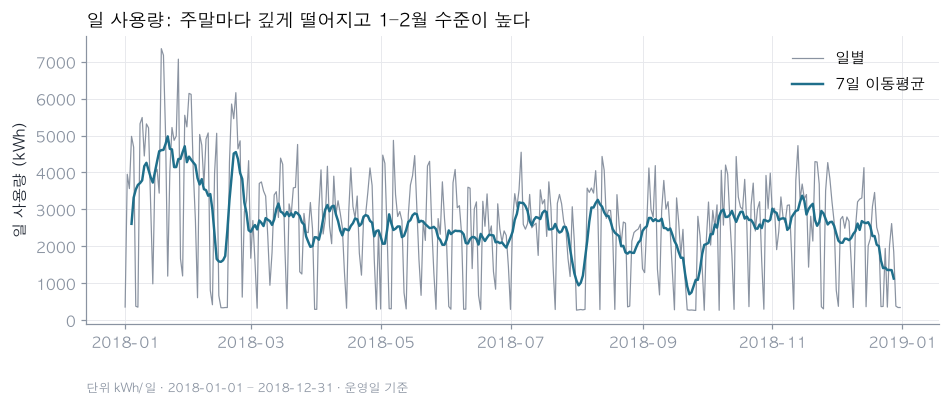

In [7]:
df = features.build(df)
daily = eda.daily_totals(df)
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.daily_timeline(daily, ax=ax)
ax.set_title("일 사용량: 주말마다 깊게 떨어지고 1–2월 수준이 높다")
plots.caption(ax, f"단위 kWh/일 · {daily.index.min():%Y-%m-%d} – {daily.index.max():%Y-%m-%d} · 운영일 기준")

Text(0.0, 1.0, '시간대 × 요일 평균 사용량')

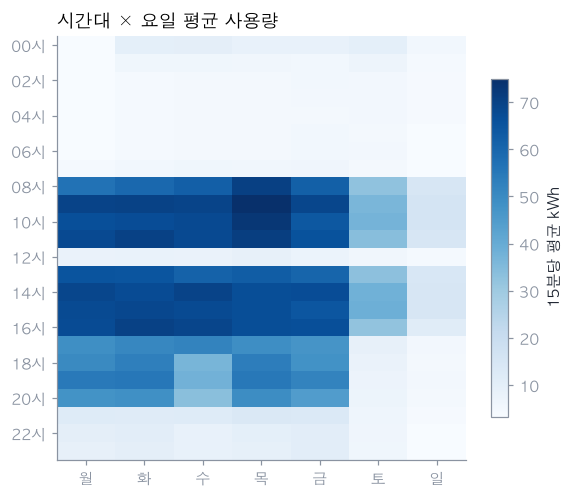

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
plots.heatmap_hour_dow(eda.hour_dow_profile(df), ax=ax)
ax.set_title("시간대 × 요일 평균 사용량")

In [9]:
eda.concentration(df), eda.idle_share(df)

({'hours': [8, 18],
  'slot_share': 0.2979452054794521,
  'kwh_share': 0.6433497630577305},
 {'threshold_kwh': 5.0,
  'slot_share': 0.5335616438356164,
  'kwh': 63618.18,
  'base_kw': 13.12})

- 평일 08–18시는 1년 15분 기록의 30%지만 사용량의 **64%**를 차지한다.
- 15분 기록의 53%는 15분 사용량 5 kWh 미만이다. 이때 전력은 중앙값 약 13 kW로, 기저 부하 상태다. 일요일 대부분과 평일 야간이 여기에 해당한다.
- 토요일은 평일과 일요일 중간이다. 오전에 가동하는 주와 쉬는 주가 섞여 있어 분산이 크다(4장 참고).

,kwh,kwh_per_day,peak_kw,pf
month,,,,
1,126238.29,4072.203,612.56,0.918
2,91497.34,3267.762,582.04,0.931
3,80230.41,2588.078,605.24,0.929
4,78769.80,2625.660,556.12,0.915
5,79059.28,2550.299,560.16,0.899
6,65404.64,2180.155,535.40,0.893
7,81674.41,2634.658,486.72,0.899
8,68559.43,2211.595,534.80,0.874
9,57883.07,1929.436,510.48,0.867


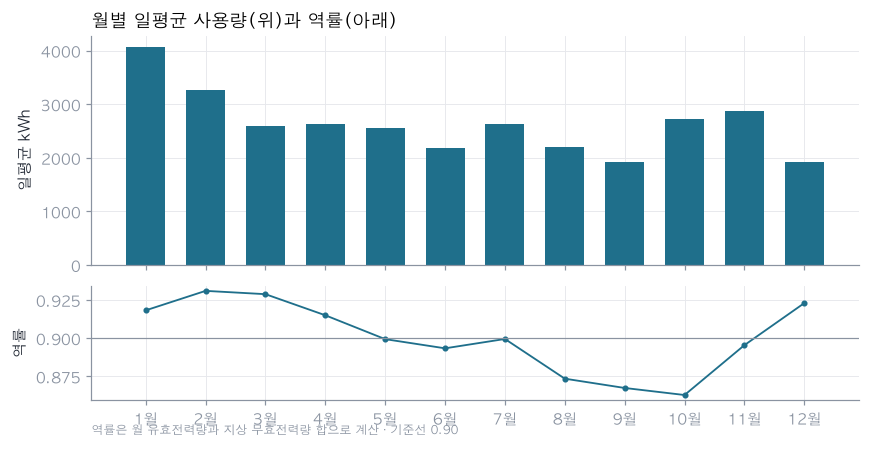

In [10]:
monthly = eda.monthly_summary(df)
top, bottom = plots.monthly(monthly)
top.set_title("월별 일평균 사용량(위)과 역률(아래)")
plots.caption(bottom, "역률은 월 유효전력량과 지상 무효전력량 합으로 계산 · 기준선 0.90")
monthly[["kwh", "kwh_per_day", "peak_kw", "pf"]]

1월의 일평균 사용량(4,072 kWh)은 연평균(2,629 kWh)의 1.5배다. 차이는 주로 야간에서 난다.

In [11]:
eda.night_load(df)

month
1     18.088
2     17.077
3      4.421
4      3.896
5      3.419
6      3.193
7      3.444
8      3.079
9      3.028
10     4.424
11     5.006
12     3.966
Name: night_mean_kwh, dtype: float64

1–2월에는 야간(21–08시) 15분 평균 사용량이 18.1, 17.1 kWh다. 3월 이후에는 3.0–5.0 kWh다. 겨울 두 달은 야간에도 가동했고, 3월부터 주간 위주로 바뀐 것으로 보인다.

역률은 10월에 0.863으로 가장 낮다.

,slots,kwh,mean_kwh,median_kwh,lag_kvarh,slot_share,kwh_share,pf
load_type,,,,,,,,
Light_Load,18072,155892.81,8.626,3.310,126581.10,0.516,0.162,0.776
Medium_Load,9696,372766.54,38.445,34.435,139722.82,0.277,0.388,0.936
Maximum_Load,7272,430977.36,59.265,56.630,190455.92,0.208,0.449,0.915


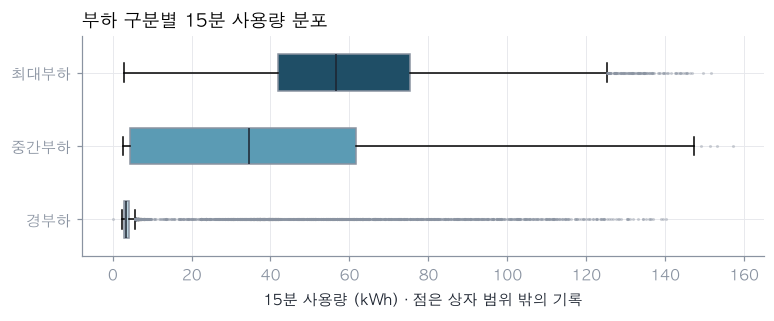

In [12]:
lt = eda.load_type_summary(df)
fig, ax = plt.subplots(figsize=(8, 2.6))
plots.load_type_distribution(df, ax=ax)
ax.set_title("부하 구분별 15분 사용량 분포")
lt

Light 시간대는 1년의 52%를 차지하지만 중앙값이 3.3 kWh로 대부분 정지 상태다. Maximum 시간대는 시간 비중 21%에 사용량의 45%를 쓴다.

,slots,kwh,lag_kvarh,pf
0–5,18696,63618.18,60127.58,0.727
5–20,2526,18320.74,5468.10,0.958
20–40,2631,85998.60,24887.01,0.961
40–60,4807,243989.31,113664.56,0.906
60–80,3063,209029.96,104249.30,0.895
80–200,3317,338679.92,148363.29,0.916


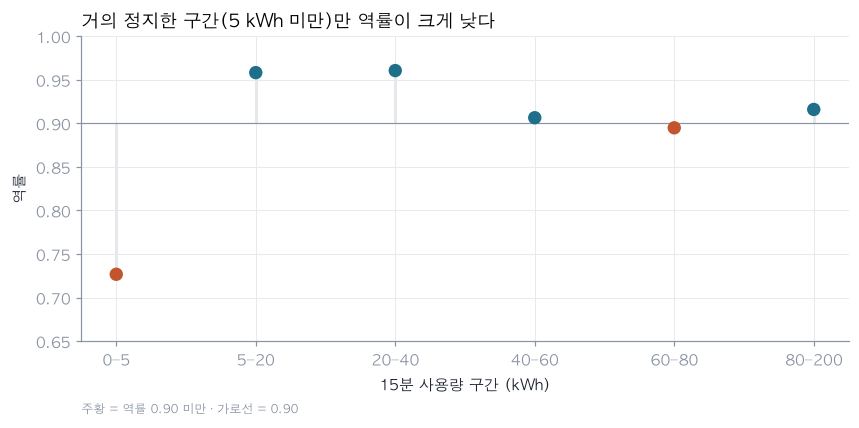

In [13]:
pf_bins = eda.pf_by_load_bin(df)
ax = plots.pf_by_load(pf_bins)
ax.set_title("거의 정지한 구간(5 kWh 미만)만 역률이 크게 낮다")
plots.caption(ax, "주황 = 역률 0.90 미만 · 가로선 = 0.90")
pf_bins

역률이 낮은 주원인은 **거의 정지한 구간**이다. 15분 5 kWh 미만에서는 역률이 0.73이다. 설비가 멈춰 있어도 변압기와 모터의 여자 전류(자화 전류) 때문에 무효전력이 계속 흐르기 때문이다. 그 밖의 구간은 0.89–0.96으로 단조 관계는 아니다.

In [14]:
corr = eda.correlations(df)  # Spearman 순위 상관(eda.correlations 참고)
corr

,kwh,lag_kvarh,lead_kvarh,co2_t,lag_pf,lead_pf,hour,is_weekend
kwh,1.000,0.645,-0.132,0.882,0.375,0.194,0.299,-0.314
lag_kvarh,0.645,1.000,-0.720,0.774,-0.350,0.744,-0.076,-0.377
lead_kvarh,-0.132,-0.720,1.000,-0.291,0.756,-0.967,0.395,0.278
co2_t,0.882,0.774,-0.291,1.000,0.239,0.335,0.238,-0.295
lag_pf,0.375,-0.350,0.756,0.239,1.000,-0.735,0.538,0.142
lead_pf,0.194,0.744,-0.967,0.335,-0.735,1.000,-0.377,-0.309
hour,0.299,-0.076,0.395,0.238,0.538,-0.377,1.000,0.000
is_weekend,-0.314,-0.377,0.278,-0.295,0.142,-0.309,0.000,1.000


Spearman 상관으로 보면 `kwh`와 `co2_t`는 0.88이다. CO₂는 사용량에서 계산된 값에 가깝다(4장). `lag_kvarh`도 사용량과 0.64로 함께 움직인다.

## 4. 통계 검정

구현: `src/steelenergy/stats.py`

15분 기록은 자기상관이 강하다. 3만 5천 행으로 검정하면 독립성 가정이 깨지고 p값이 무의미하게 작아진다. 그래서 다음과 같이 했다.
- **일 단위 집계**를 관측 단위로 쓴다.
- 효과크기의 신뢰구간은 **주 단위 블록 부트스트랩**으로 구한다. 월–일 한 주를 통째로 복원추출하므로 같은 주 안의 의존성이 유지된다.
- p값은 Holm 방법으로 보정했다. 여러 검정을 동시에 할 때 우연히 유의해지는 것을 막는 보정이다.

하루 합계도 전날과 연관이 있다(아래 1일 시차 자기상관). 그래서 순위 검정의 p값은 독립을 가정한 만큼 실제보다 작게 나온다. 결론은 효과크기와 블록 부트스트랩 신뢰구간으로 내리고, p값은 참고용으로만 둔다.

In [15]:
daily["kwh"].autocorr(lag=1)

np.float64(0.4043793466976168)

In [16]:
tests = stats.run_tests(df, daily)
tests[["question", "n", "test", "effect_name", "effect", "ci_low", "ci_high", "p_holm"]]

,question,n,test,effect_name,effect,ci_low,ci_high,p_holm
0,평일과 주말의 일 소비량 차이,365,Mann–Whitney U,Cliff's δ,0.810,0.731,0.885,3.677e-33
1,토요일과 일요일의 일 소비량 차이(같은 주끼리 대응),52,Wilcoxon signed-rank,Cliff's δ,0.541,0.375,0.698,1.388e-06
2,부하 유형(Light/Medium/Maximum)별 평균 소비 수준,303,Friedman χ²,Kendall's W,0.844,0.789,0.903,3.312e-111
3,월별 평일 일 소비량 차이(계절성),261,Kruskal–Wallis H,ε²,0.249,0.132,0.480,6.434e-11


- **평일과 주말:** Cliff's δ = 0.81 [0.73, 0.88]. δ는 한쪽 값이 다른 쪽보다 클 확률에서 반대 확률을 뺀 값이다. 무작위로 고른 평일이 주말보다 사용량이 많을 확률은 P = (1 + δ) / 2 ≈ 91%다.
- **토요일과 일요일:** δ = 0.54. 토요일 가동 여부가 주마다 다르다.
- **부하 구분 간 수준 차이:** Kendall's W = 0.84로 매우 일관적이다. W는 0–1이며 1이면 모든 날의 순위가 같다는 뜻이다. 세 부하 구분이 모두 있는 303일만 썼다.
- **평일만 본 월별 차이:** ε² = 0.25로, 월이 일 사용량 분산의 약 25%를 설명한다. 다만 신뢰구간이 0.13–0.48로 넓다.

In [17]:
stats.emission_factor(daily)

{'t_per_mwh': 0.433424053988418,
 'ratio_of_sums': 0.4207946567613071,
 'r2_daily': 0.9719056947964527}

연간 합계로 계산한 배출계수는 **0.421 tCO₂/MWh**다. 일 단위로 원점을 지나는 회귀를 하면 0.433이고 R²는 0.97이다. 보고서와 대시보드는 연간 합계 기준을 쓴다.

CO₂는 사용량에 계수를 곱한 값에 가깝다. 그래서 CO₂를 사용량 예측의 입력으로 쓰면 정답을 거의 그대로 넣는 셈이 된다(누수).

## 5. 사용량 예측 (15분 앞)

구현: `src/steelenergy/models/split.py`, `models/regress.py`

**설정**
- t 시점의 kWh를 t−1까지의 정보만으로 예측한다.
- 입력은 달력 피처와 과거 사용량(lag·rolling)뿐이다. 같은 구간의 무효전력·역률·CO₂는 쓰지 않는다.
- 학습 2018-01-08–2018-09-30, 검증 10월, 테스트 11–12월로 나눴다. 1주 전 값(`kwh_lag672`)이 필요해서 첫 7일(2018-01-08 이전)은 빠진다.
- 모델 선택은 검증으로만 했다. 테스트는 학습+검증(1–10월)으로 다시 학습한 뒤 한 번만 평가했다.

**모델**
- 기준선 세 가지: 직전값 그대로, 하루 전 같은 시각, 일주일 전 같은 시각
- 선형 회귀: Ridge(L2 정규화 선형회귀)
- 부스팅 트리: HGB(scikit-learn `HistGradientBoostingRegressor`, 결정트리를 순차적으로 쌓는 모델)

**지표**
- MAE: 평균 절대 오차(kWh)
- RMSE: 큰 오차에 더 민감한 오차
- WAPE: 총 사용량 대비 절대 오차 합(%)

구간의 절반이 3 kWh 근처라 MAPE는 쓰지 않는다. 값이 작은 구간에서 비율 오차가 폭주하기 때문이다.

In [18]:
sp = split.by_date(df)
sp.periods()

{'train': {'start': '2018-01-08', 'end': '2018-09-30', 'rows': 25536},
 'valid': {'start': '2018-10-01', 'end': '2018-10-31', 'rows': 2976},
 'test': {'start': '2018-11-01', 'end': '2018-12-31', 'rows': 5856}}

In [19]:
reg = regress.evaluate(sp)
reg.scores.rename(index=labels.REGRESSION)

,valid_mae,valid_rmse,valid_wape,test_mae,test_rmse,test_wape,test_mae_vs_best_naive
model,,,,,,,
직전값 그대로,7.063,14.522,0.248,5.157,11.814,0.207,0.000
하루 전 같은 시각,18.156,32.385,0.638,14.363,26.662,0.577,-1.785
일주일 전 같은 시각,13.374,25.532,0.470,12.723,24.375,0.512,-1.467
선형 회귀(Ridge),7.081,12.317,0.249,6.178,10.222,0.248,-0.198
부스팅 트리(HGB),4.897,10.053,0.172,3.942,8.092,0.158,0.236


- 직전값이 생각보다 강하다(MAE 5.16). 하루 전·일주일 전 값은 가동 여부가 바뀌는 날이 많아 훨씬 나쁘다.
- Ridge(6.18)는 직전값보다 못하다. 가동 시작과 정지 같은 급격한 전환은 선형 모델로 잡지 못한다.
- HGB는 테스트 MAE 3.94 kWh로 검증에서 가장 나았던 기준선('직전값 그대로') 대비 **24%** 개선했다. 같은 기간(11–12월)의 15분 평균 사용량 24.9 kWh와 견주어 보면 된다.

Text(0.0, 1.0, '테스트 기간 한 주(2018-12-03 – 2018-12-09) 예측')

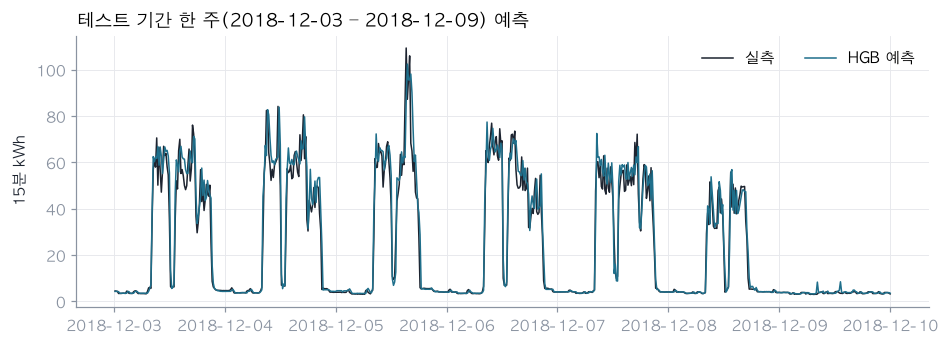

In [20]:
week = reg.test_predictions["operating_day"].between(*config.FORECAST_WEEK)
ax = plots.forecast_week(reg.test_predictions[week])  # 직전값 선은 실측과 겹쳐 생략(show_naive=True로 표시)
ax.set_title(f"테스트 기간 한 주({config.FORECAST_WEEK[0]} – {config.FORECAST_WEEK[1]}) 예측")

,mae_increase,std
직전 15분 사용량,28.092,0.379
30분 전 사용량,3.748,0.052
시각(하루 주기 성분 2),2.438,0.034
하루 중 순번(15분 단위),0.498,0.030
최근 1시간 평균,0.442,0.019
1시간 전 사용량,0.358,0.014
시각(하루 주기 성분 1),0.183,0.005
일주일 전 같은 시각,0.171,0.013


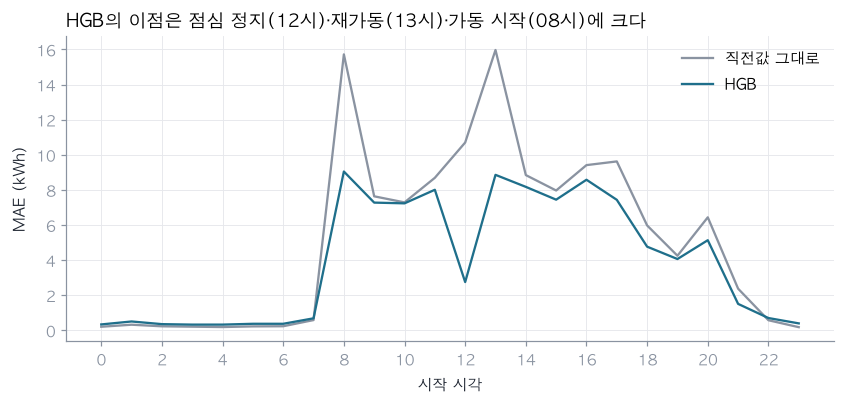

In [21]:
ax = plots.error_by_hour(reg.error_by_hour)
ax.set_title("HGB의 이점은 점심 정지(12시)·재가동(13시)·가동 시작(08시)에 크다")
reg.importance.rename(index=labels.FEATURES).head(8)

순열 중요도는 피처 하나를 무작위로 섞었을 때 MAE가 얼마나 늘어나는지를 잰다. 직전 15분 사용량의 영향이 압도적이다.

시각별로 보면 HGB의 이점은 사용량이 급변하는 시각에 몰린다. 밤(22–07시)에는 두 방법 모두 오차가 1 kWh 미만이고, 직전값이 근소하게 낫다.

## 6. 부하 구분 분류: 처음 시도와 수정

구현: `src/steelenergy/models/classify.py`

처음에는 달력 피처(요일, 시각, 월)와 과거 사용량으로 `Load_Type`을 분류했다. 검증(10월)에서 macro-F1 0.99가 나왔다. 테스트(11–12월)에서는 **0.61**로 떨어졌다. macro-F1은 세 등급을 각각 얼마나 잘 맞혔는지를 평균한 값으로, 1이 만점이다.

In [22]:
clf = classify.evaluate(sp)
clf.scores.assign(label=clf.scores.index.map(lambda m: labels.CLASSIFICATION[m][0]))

,features,valid_macro_f1,valid_accuracy,test_macro_f1,test_accuracy,label
model,,,,,,
schedule_lookup,calendar,0.926,0.925,0.540,0.617,시간표 조회
hgb_no_season,calendar+month+history,0.991,0.991,0.606,0.725,부스팅 트리(HGB)
hgb_season_month_first,calendar+month+season+history,0.991,0.991,0.607,0.727,부스팅 트리(HGB)
hgb_season_month_last,calendar+month+season+history,0.991,0.991,0.945,0.956,부스팅 트리(HGB)
schedule_lookup_season,calendar+season,0.926,0.925,0.899,0.904,시간표 조회
logistic,calendar+season+history,0.901,0.912,0.536,0.677,로지스틱 회귀
hgb,calendar+season+history,0.993,0.992,0.966,0.969,부스팅 트리(HGB)
hgb_same_interval,calendar+season+history+same-interval,0.991,0.991,0.970,0.974,부스팅 트리(HGB)


초기 모델(계절 미반영)의 테스트 혼동행렬을 보면 오차가 거의 전부 Medium과 Maximum 사이에서 난다.

In [23]:
clf.confusions["hgb_no_season"]

,Light_Load,Medium_Load,Maximum_Load
Light_Load,3070,15,27
Medium_Load,7,782,779
Maximum_Load,0,784,392


월·시간별로 가장 흔한 라벨을 펼쳐 보면 원인이 드러난다.

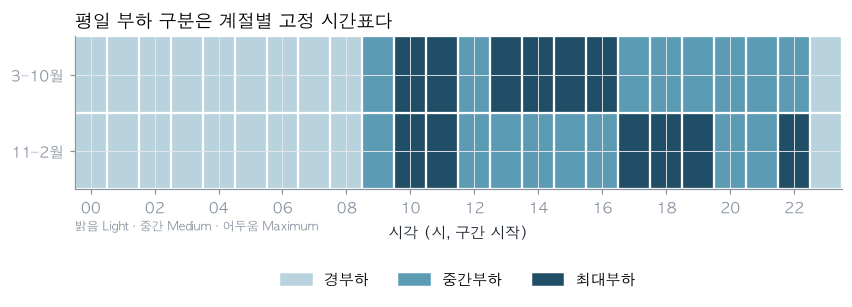

In [24]:
schedule = eda.tou_schedule(df)
ax = plots.tou_schedule(schedule)
ax.set_title("평일 부하 구분은 계절별 고정 시간표다")
plots.caption(ax, "밝음 Light · 중간 Medium · 어두움 Maximum")

`Load_Type`은 측정된 부하 상태가 아니다. **계절에 따라 바뀌는 시간대별 요금 구간(TOU, 계시별 요금) 라벨**에 가깝다.
- 3–10월: Maximum이 10–12시, 13–17시다.
- 11–2월: Maximum이 10–12시, 17–20시, 22–23시로 바뀐다.
- 검증 기간인 10월은 여름 시간표라서 이 변화를 보지 못했다.

수정한 내용은 두 가지다.
1. `is_winter`(11–2월) 피처를 추가했다.
2. `month`를 모델 입력에서 뺐다.

두 번째 수정의 이유는 위 표의 `hgb_season_month_first`와 `hgb_season_month_last`에 있다. 두 행은 같은 피처를 쓰고 열 순서만 다르다. 그런데 테스트 F1이 0.61과 0.94로 갈린다.
- 학습 기간(1–10월)에는 `is_winter == 1`과 `month <= 2`가 정확히 같은 행을 가리킨다.
- 트리는 둘 중 하나로 분기하고, 동률이면 열 순서로 고른다.
- `month`로 분기한 모델은 처음 보는 11·12월을 여름(3–10월) 쪽으로 보낸다.

아래 셀에서 시드(0, 42)를 바꿔도 결과가 같고 열 순서에만 달려 있음을 확인한다. 우연에 기대는 모델이므로 `month`를 뺐다.

In [25]:
classify.column_order_check(sp)

seed,0,42
model,,
hgb_season_month_first,0.608,0.607
hgb_season_month_last,0.949,0.945


열 순서가 같으면 시드와 무관하게 같은 점수가 나온다.

수정 후 HGB의 테스트 macro-F1은 **0.966**다. 같은 구간의 전기 측정값을 더해도 0.970으로 거의 같다. 라벨이 시간표로 정해진다는 해석과 맞는 결과다.

**이 점수는 독립적인 확인이 아니다.** 11–12월 결과를 보고 모델을 고쳤으므로, 같은 기간의 점수는 탐색 결과다. 그래서 시간 방향을 뒤집은 별도 분할로 다시 확인한다. 3–12월로 학습하고 또 다른 겨울 기간인 1–2월로 평가한다. 1–2월도 처음 학습과 시간표 분석에 쓰였으므로 완전히 새로운 자료는 아니다. 새 연도 자료가 생기면 그것으로 확인하는 것이 맞다.

In [26]:
classify.reverse_check(df)

,macro_f1,accuracy
model,,
schedule_lookup,0.568,0.663
schedule_lookup_season,0.883,0.888
hgb,0.956,0.956


1–2월에서 최종 모델은 0.956, 요일·시각·계절 시간표는 0.883이다. 계절을 빼면 0.568에 그친다. 계절별 시간표라는 결론이 뒤집은 분할에서도 유지된다.

Text(0.0, 1.0, 'HGB(계절 반영) 테스트 혼동행렬')

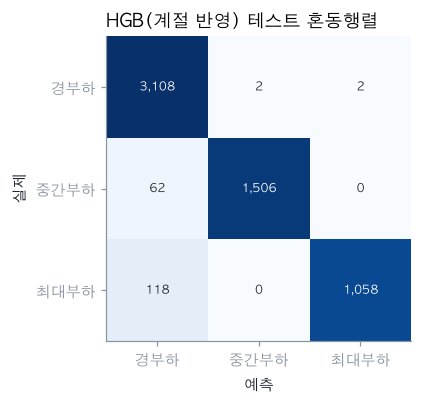

In [27]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
plots.confusion(clf.confusion, ax=ax)
ax.set_title("HGB(계절 반영) 테스트 혼동행렬")

최종 모델의 남은 오분류는 실제 Maximum을 Light로 본 118건과 실제 Medium을 Light로 본 62건이 대부분이다. 평일·주말로 나누면 다음과 같다.

In [28]:
clf.errors_by_daytype

,slots,errors,error_rate,share_of_errors
is_weekend,,,,
주말,1728,124,0.072,0.674
평일,4128,60,0.015,0.326


오분류의 67%가 주말에서 나온다. 주말은 테스트 기간 기록의 30%다. 학습 기간에 겨울 주말은 1–2월분밖에 없었다.

## 7. 휴무와 이상 탐지

구현: `src/steelenergy/anomaly.py`, `eda.holiday_operation`, `eda.weekday_shutdowns`. 기준값은 `config.py`의 `SHUTDOWN_RATIO`, `ANOMALY_Z_DAY`, `ANOMALY_Z_INTERVAL`, `ANOMALY_MIN_RUN`이다.

**처음 시도**(작업 기록이며 현재 코드에는 남겨 두지 않았다)는 달력 피처만으로 기대 사용량을 예측하고(이전 달까지로 학습), 그 잔차가 큰 구간을 이상으로 보는 방식이었다. 결과는 15분 기록의 약 15%가 이상으로 잡혔다. 1–2월의 야간 가동이 3월부터 줄어든 것처럼, 운영 방식이 바뀌면 그 이후가 전부 이상으로 표시되었다. 이 방식은 폐기했다.

최종 방식은 세 가지다.
- **공휴일**: 미리 알 수 있는 정보이므로 2018년 한국 공휴일 달력(`config.KR_HOLIDAYS_2018`)으로 따로 정리한다. 주말과 겹친 공휴일은 원래 쉬는 날이라 휴무 판정에서 뺀다.
- **일 단위 이상**: 각 날을 직전 4주 같은 요일(공휴일 제외)의 중앙값과 비교한다. 평일·토·일별로 robust z를 계산하고 |z| ≥ 4이면 이상으로 본다.
  - robust z는 평균·표준편차 대신 중앙값과 MAD(중앙값 절대편차)로 표준화한 편차 점수다. 이상치 몇 개에 기준이 흔들리지 않는다.
  - 기대값은 과거만 참조하므로 운영 방식이 바뀌면 한 번 표시된 뒤 기준에 흡수된다.
  - 다만 점수의 척도(잔차의 중앙값·MAD)는 1년 전체로 계산한다. 그날 바로 울리는 경보가 아니라 사후 점검이다.
- **15분 단위 점검 구간**: 월별 확장 창(매달 그 이전 모든 달로 다시 학습)으로 만든 15분 앞 예측의 잔차를 본다. 잔차를 (평일·토·일, 시각) 칸마다 중앙값과 MAD로 표준화해 z를 만든다. 칸마다 평소 흔들림이 다르기 때문이다(`anomaly.robust_z`, `anomaly.flag`).

In [29]:
holidays = eda.holiday_operation(daily)
holidays[["holiday", "is_weekend", "kwh", "ratio_to_weekday", "shutdown"]]

,holiday,is_weekend,kwh,ratio_to_weekday,shutdown
2018-01-01,신정,False,351.86,0.110,True
2018-02-15,설날 연휴,False,334.54,0.105,True
2018-02-16,설날,False,331.64,0.104,True
2018-02-17,설날 연휴,True,339.23,0.106,False
2018-03-01,삼일절,False,1674.44,0.525,False
2018-05-05,어린이날,True,307.44,0.096,False
2018-05-07,대체공휴일,False,4868.65,1.526,False
2018-05-22,부처님오신날,False,2157.01,0.676,False
2018-06-06,현충일,False,3042.13,0.953,False
2018-06-13,지방선거,False,1392.99,0.436,False


공휴일 18일 가운데 3일은 주말과 겹친다. 평일 공휴일 15일 중 7일은 휴무였다(평일 중앙값의 20% 미만): 1/1 신정, 2/15 설날 연휴, 2/16 설날, 9/24 추석, 9/25 추석 연휴, 9/26 대체공휴일, 12/25 성탄절.

나머지 공휴일에는 가동했고, 가동 수준은 날마다 달랐다: 대체공휴일(153%), 현충일(95%), 광복절(86%), 한글날(81%), 부처님오신날(68%), 개천절(64%), 삼일절(52%), 지방선거(44%).

이 공장은 명절과 신정·성탄절에 쉬고 나머지 공휴일에는 대체로 가동한다.

In [30]:
days = anomaly.daily_deviation(daily)
days[days["flag"]][["weekday", "kwh", "expected_kwh", "z"]]

,weekday,kwh,expected_kwh,z
operating_day,,,,
2018-02-14,Wednesday,663.18,4273.235,-4.222
2018-07-15,Sunday,3529.94,561.185,5.368


공휴일을 제외하면 일 단위 이상은 2일이다.
- 2/14(수): 실측 663 kWh, 평소 4,273 kWh, z -4.2. 설 연휴 전날. 연휴에 앞서 일찍 멈춘 것으로 보인다.
- 7/15(일): 실측 3,530 kWh, 평소 561 kWh, z 5.4. 일요일인데 평일 수준으로 썼다. 특근일 가능성이 있다.

비교할 이전 같은 요일 4번이 쌓이기 전인 1/30 이전은 판정하지 않았다. 사유는 전력 기록만으로 확정할 수 없으므로 위 설명은 달력에 비춘 추정이다.

임계값 바로 아래(3 ≤ |z| < 4)에는 2/24(토, z 3.0), 5/1(화, z -3.7), 7/8(일, z 3.9), 8/2(목, z -3.2), 11/4(일, z 3.8), 12/16(일, z 3.0)가 있다. 이 가운데 연속 휴무의 일부인 날이 있는지 앞뒤 날짜를 확인해 본다.

In [31]:
runs = eda.shutdown_runs(eda.weekday_shutdowns(daily))
longest = runs.loc[runs["days"].idxmax()]  # 가장 긴 연속 휴무와 앞뒤 날짜
daily.loc[longest["start"] - pd.Timedelta(days=2):longest["end"] + pd.Timedelta(days=4), ["kwh"]].T.round(0)

operating_day,2018-07-30,2018-07-31,2018-08-01,2018-08-02,2018-08-03,2018-08-04,2018-08-05,2018-08-06,2018-08-07
kwh,3070.0,2109.0,268.0,276.0,285.0,275.0,288.0,3575.0,3458.0


휴무가 여러 날 이어지면 z 기준으로는 잘 잡히지 않는다. 평일 잔차의 MAD가 커서 휴무일의 z가 −3 언저리에 머물기 때문이다.

그래서 휴무는 z 대신 단순한 규칙으로 따로 판정한다. 공휴일이 아닌 평일 중 사용량이 평일 중앙값의 20% 미만인 날을 휴무로 본다.

In [32]:
eda.weekday_shutdowns(daily)

,kwh,dow,ratio_to_weekday
operating_day,,,
2018-05-01,298.65,1,0.094
2018-08-01,268.01,2,0.084
2018-08-02,276.00,3,0.086
2018-08-03,285.38,4,0.089
2018-12-31,339.08,0,0.106


공휴일이 아닌 평일 휴무는 5일이다.
- 5/1: 근로자의 날
- 8/1: 8월 초 연속 저사용일(여름휴가 추정)
- 8/2: 8월 초 연속 저사용일(여름휴가 추정)
- 8/3: 8월 초 연속 저사용일(여름휴가 추정)
- 12/31: 연말

이상 탐지에 잡힌 날과 휴무일은 모두 달력 일정과 맞아떨어진다. 다만 실제 사유(휴가, 특근, 설비 문제)는 전력 기록만으로 확정할 수 없고 운영 기록으로 확인해야 한다.

Text(0.0, 1.0, '공휴일을 제외한 일 단위 이상은 2일')

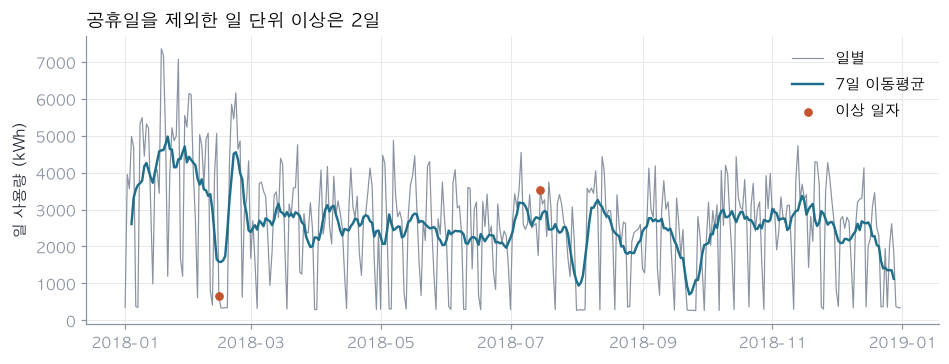

In [33]:
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.daily_timeline(daily, days[days["flag"]], ax=ax)
ax.set_title(f"공휴일을 제외한 일 단위 이상은 {int(days['flag'].sum())}일")

In [34]:
intervals = anomaly.flag(df, regress.out_of_fold_forecast(split.monthly_folds(df)))
anomaly.sensitivity(intervals)

,z,flag_rate,episodes
0,3,0.099,442
1,4,0.069,317
2,5,0.052,241
3,6,0.044,210
4,8,0.033,174


15분 단위 잔차는 꼬리가 매우 두껍다. 임계값을 3에서 8로 올려도 플래그 비율이 9.9%에서 3.3%로 천천히 줄 뿐 뚜렷한 끊김이 없다. 설비가 켜지고 꺼지는 순간이 매번 큰 잔차를 만들기 때문이다.

그래서 15분 단위 결과는 현장에서 확인할 **점검 목록**으로만 쓴다. |z| ≥ 6인 15분 기록이 2개 이상(30분 이상) 이어진 연속 이벤트만 남겼다.

In [35]:
episodes = anomaly.episodes(intervals)
episodes.head(10)

,start,end,slots,direction,kwh,expected_kwh,excess_kwh,max_abs_z,is_weekend,load_type,holiday
0,2018-11-27 21:15:00,2018-11-28 06:30:00,37,high,872.24,626.832,245.408,24.131,False,Light_Load,NaN
1,2018-02-11 14:00:00,2018-02-11 23:45:00,39,low,171.87,397.788,-225.918,19.510,True,Light_Load,NaN
2,2018-02-27 21:00:00,2018-02-28 00:00:00,12,low,88.59,289.561,-200.971,85.557,False,Light_Load,NaN
3,2018-02-26 21:00:00,2018-02-27 00:15:00,13,low,79.33,258.730,-179.400,40.651,False,Light_Load,NaN
4,2018-02-16 21:00:00,2018-02-17 00:15:00,13,low,44.79,219.006,-174.216,50.623,False,Light_Load,설날
5,2018-02-24 19:30:00,2018-02-24 21:45:00,9,high,746.11,578.337,167.773,106.677,True,Medium_Load,NaN
6,2018-07-15 13:45:00,2018-07-15 16:45:00,12,high,1121.05,960.762,160.288,33.422,True,Maximum_Load,NaN
7,2018-10-23 21:30:00,2018-10-23 23:00:00,6,high,370.12,236.366,133.754,157.954,False,Medium_Load,NaN
8,2018-02-24 22:00:00,2018-02-24 23:45:00,7,high,579.17,447.839,131.331,109.292,True,Maximum_Load,NaN
9,2018-02-15 21:00:00,2018-02-16 00:00:00,12,low,40.39,169.547,-129.157,36.858,False,Light_Load,설날 연휴


In [36]:
anomaly.isolation_forest_agreement(df, intervals)

{'residual_rate': 0.04388098802395209,
 'iforest_rate': 0.04388098802395209,
 'share_of_residual_flags_also_iforest': 0.21108742004264391,
 'jaccard': 0.11799761620977355,
 'chance_overlap': 0.04388098802395209}

Isolation Forest는 전기 측정값만 보고 이상을 고르는 다른 방식의 알고리즘이다. 잔차 기반 플래그 중 21%는 Isolation Forest도 이상으로 잡았다. 같은 비율로 무작위로 플래그를 찍었을 때 기대되는 겹침은 4.4%다. 두 방법은 서로 다른 것을 본다. 이 정도 일치를 근거로 '확정 이상'이라고 할 수는 없다.

## 8. 절감 시나리오

구현: `src/steelenergy/scenarios.py`

이 데이터에는 요금 정보가 없다. 요금 단가와 역률 할증 규칙은 `config.TARIFF_ASSUMPTIONS`에 둔 **가정값**이다. 금액은 구조를 비교하는 용도로만 해석해야 한다.

In [37]:
config.TARIFF_ASSUMPTIONS

{'currency': 'KRW',
 'energy_rate_per_kwh': {'Light_Load': 95.0,
  'Medium_Load': 140.0,
  'Maximum_Load': 210.0},
 'demand_rate_per_kw_month': 8300.0,
 'pf_threshold': 0.9,
 'pf_penalty_rate_per_pct': 0.002,
 'source': '가정값 (국내 산업용 TOU 요금 구조를 단순화한 예시 단가)'}

**(a) 역률 보상**: 역률이 목표값보다 낮은 15분 기록의 지상 무효전력량을 목표 수준까지 줄인다. 콘덴서 설치를 가정한 계산이다. 유효전력량(kWh)과 CO₂는 변하지 않는다. 바뀌는 것은 다음 세 가지다.
- 연간 무효전력량(kVarh). 콘덴서 용량(kVar)과는 다른 값이다.
- 피상전력 최대치: 변압기가 감당하는 전체 전력(kVA)
- 역률 할증

In [38]:
pf = scenarios.pf_grid(df)
pf.assign(**{c: pf[c] / 1e4 for c in ["surcharge_before", "surcharge_after"]}).round(3)

,target_pf,kvarh_before,kvarh_after,peak_kva_before,peak_kva_after,annual_pf_before,annual_pf_after,surcharge_before,surcharge_after,kwh_change
0,0.90,456759.84,369903.615,701.381,698.578,0.903,0.933,26.22,0.0,0.0
1,0.92,456759.84,342605.114,701.381,683.391,0.903,0.942,26.22,0.0,0.0
2,0.94,456759.84,303982.705,701.381,668.851,0.903,0.953,26.22,0.0,0.0
3,0.95,456759.84,279677.120,701.381,661.811,0.903,0.960,26.22,0.0,0.0
4,0.96,456759.84,251432.838,701.381,654.917,0.903,0.967,26.22,0.0,0.0
5,0.98,456759.84,178894.619,701.381,641.551,0.903,0.983,26.22,0.0,0.0


목표 역률을 0.95로 잡으면 다음과 같이 바뀐다.
- 지상 무효전력량: 457 → 280 MVarh(39% 감소)
- 피상전력 최대치: 701 → 662 kVA

가정한 요금 체계에서 역률 할증은 연 26만 원 수준이다. 할증은 7개월에 붙지만 88%가 8–10월에 몰려 있다. 금액보다는 변압기 여유와 손실 감소 쪽 효과가 크다.

**(b) 피크 부하 이동**: 최대부하(Maximum) 시간대 사용량의 일부를 같은 날 경부하(Light) 시간대로 고르게 옮긴다. 옮기는 사용량에 딸린 무효전력량도 원래 비율대로 함께 옮긴다. 총 kWh와 CO₂는 보존되고, 바뀌는 것은 시간대별 요금과 최대 수요다.

*작업 중 수정:* 처음 구현에서는 무효전력량을 받는 쪽(경부하 시간대)의 비율로 다시 계산했다. 그러자 정지 구간의 나쁜 역률이 옮긴 부하에 붙어 할증이 늘어나는 것처럼 나왔다. 지금은 원래 비율을 유지하고, 하루 단위로 kWh와 kVarh가 모두 보존되는지 테스트(`test_shift_conserves_daily_*`)로 확인한다.

In [39]:
cost_cols = ["energy_cost_after", "demand_cost_after", "surcharge_after", "total_cost_after"]
grid = scenarios.shift_grid(df).set_index("fraction")
(grid[cost_cols] - grid[[c.replace("after", "before") for c in cost_cols]].values).div(1e4).round(0).join(
    grid["mean_monthly_peak_kw_after"].round(0))

,energy_cost_after,demand_cost_after,surcharge_after,total_cost_after,mean_monthly_peak_kw_after
fraction,,,,,
0.00,0.0,0.0,0.0,0.0,564.0
0.05,-248.0,-28.0,-0.0,-276.0,561.0
0.10,-496.0,16.0,-1.0,-481.0,565.0
0.15,-743.0,65.0,-1.0,-679.0,570.0
0.20,-991.0,116.0,-2.0,-877.0,576.0
0.25,-1239.0,166.0,-2.0,-1075.0,581.0
0.30,-1487.0,217.0,-3.0,-1273.0,586.0


위 표는 만 원 단위의 변화량이다. 최대부하 시간대 사용량의 10%를 옮기면 가정 요금 기준 연 481만 원(2.2%)이 줄어든다.
- 전력량요금: −496만 원
- 기본요금: +16만 원

월 최대 수요의 평균(현재 564 kW)은 이동 비율에 따라 5%에서 561 kW, 10%에서 565 kW, 15%에서 570 kW, 20%에서 576 kW, 25%에서 581 kW, 30%에서 586 kW가 된다. 이동 비율 10%부터는 기본요금이 오히려 늘어난다. 경부하 시간대는 주로 야간이라, 이미 가동 중인 야간에 부하가 더해지면 새 피크가 생긴다. 실제로 옮길 수 있는 공정이 있는지는 이 데이터로 알 수 없다.

## 9. 정리와 한계

맨 위의 질문과 답 표가 이 노트북의 결론이다.

**한계**
- 공장 한 곳의 1년치 데이터다. 겨울 시간표 기간은 1–2월과 11–12월뿐이라 계절 패턴을 학습할 표본이 적다.
- 생산량, 공정, 설비 정보가 없어 사용량이 왜 바뀌었는지는 추정만 할 수 있다.
- 요금은 가정값이다. CO₂는 0.01 t 단위로 반올림되어 있다.
- 공휴일 달력은 휴무·이상 분석에만 썼다. 예측·분류 모델에 공휴일과 겨울 주말 정보를 넣는 것은 다음 단계로 남긴다.